### Visualização de dados para identificação e comparação de eventos

Este notebook tem como objetivo apresentar pequenas partes dos dados com diferentes classes de eventos para comparar e perceber visualmente a diferença entre elas.

In [1]:
import mne
import numpy as np
import matplotlib.pyplot as plt

# Carregando os dados do arquivo .fif de epochs
epochs = mne.read_epochs('eldBETA_s01_epo_filtrado.fif')

print("Classes (frequências) disponíveis:", list(epochs.event_id.keys()))

Reading c:\Users\Pichau\Desktop\topicosEspeciaisSistemas\eldBETA_s01_epo_filtrado.fif ...


C:\Users\Pichau\AppData\Local\Temp\ipykernel_17044\1832374736.py:6: RuntimeWarning: This filename (eldBETA_s01_epo_filtrado.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs = mne.read_epochs('eldBETA_s01_epo_filtrado.fif')


    Found the data of interest:
        t =       0.00 ...    6000.00 ms
        0 CTF compensation matrices available
Adding metadata with 3 columns
63 matching events found
No baseline correction applied
0 projection items activated
Classes (frequências) disponíveis: ['1', '2', '3', '4', '5', '6', '7', '8', '9']


In [4]:
def plots_evoked(evoked_data, channels_to_plot=None, color="blue"):
    """
    Plota os dados evocados para um conjunto de canais.
    """ 
    data = evoked_data.get_data() # (channels, times)
    times = evoked_data.times
    ch_names = evoked_data.ch_names
    
    if channels_to_plot:
        idx = [ch_names.index(ch) for ch in channels_to_plot if ch in ch_names]
        data = data[idx]
        ch_names = [ch_names[i] for i in idx]

    n_channels = len(ch_names)
    ncols = 2
    nrows = int(np.ceil(n_channels / ncols))
    
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 2.5 * nrows), sharex=True)
    axes = axes.flatten()

    for i, channel_name in enumerate(ch_names):
        ax = axes[i]

        ax.plot(times, data[i], label=channel_name, color=color)
        ax.set_title(f"Canal: {channel_name}")
        ax.grid(True, linestyle="--", alpha=0.5)

        # rótulo do eixo Y apenas na primeira coluna
        if i % 2 == 0:
            ax.set_ylabel("Amplitude")
        # rótulo do eixo X apenas na última linha
        if i >= (nrows * ncols) - 2:
            ax.set_xlabel("Tempo (s)")
            
    for j in range(n_channels, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

Média dos trials de 8 Hz:


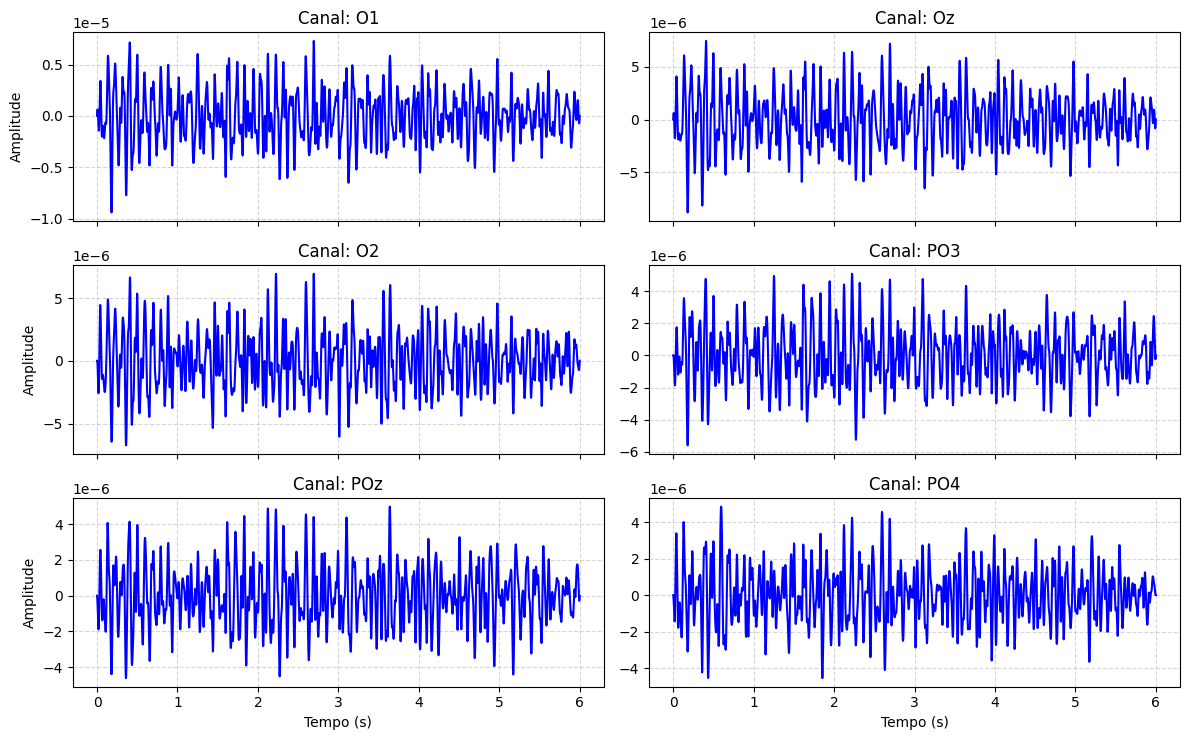

Média dos trials de 1 Hz:


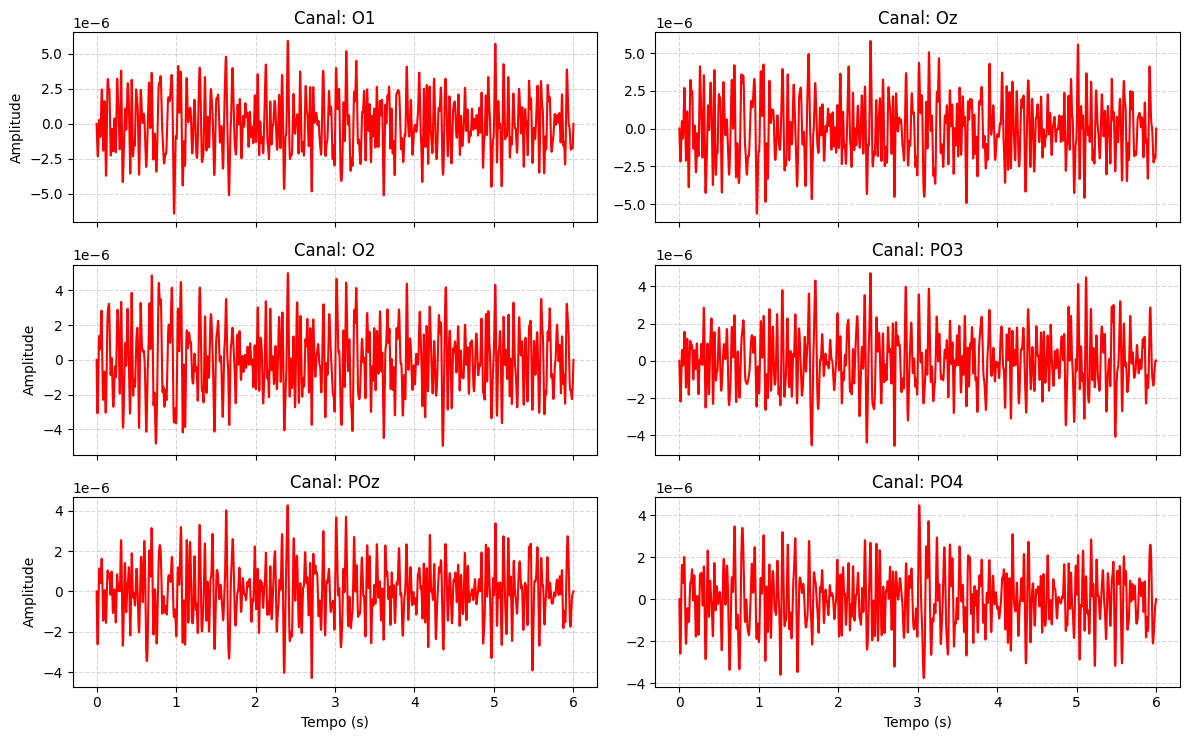

In [8]:
canais_occipitais = ['O1', 'Oz', 'O2', 'PO3', 'POz', 'PO4']

# Plotando a MÉDIA para a classe de 8 Hz (Azul)
print("Média dos trials de 8 Hz:")
plots_evoked(epochs['8'].average(), channels_to_plot=canais_occipitais, color="blue")

# Plotando a MÉDIA para a classe de 4 Hz (Vermelho)
print("Média dos trials de 1 Hz:")
plots_evoked(epochs['1'].average(), channels_to_plot=canais_occipitais, color="red")

**Continuação da atividade**: Procurem realizar comparações diferentes com relação as entradas. 

Compare diferentes classes utilizando por exemplo:
- Média de todos os eletrodos
- Comparação com partes de "hit" e "miss" separados (unica amostra)

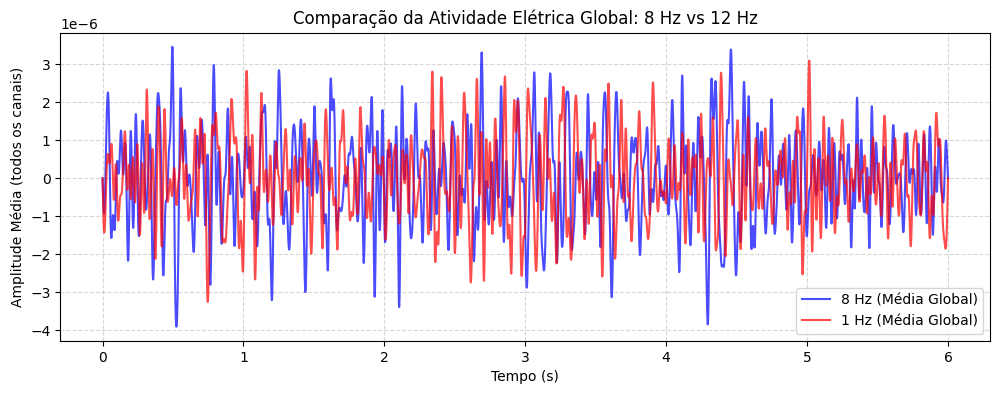

In [10]:
evoked_8hz_all = epochs['8'].average().pick('eeg').data.mean(axis=0)
evoked_1hz_all = epochs['1'].average().pick('eeg').data.mean(axis=0)
times = epochs.times

plt.figure(figsize=(12, 4))
plt.plot(times, evoked_8hz_all, label='8 Hz (Média Global)', color='blue', alpha=0.7)
plt.plot(times, evoked_1hz_all, label='1 Hz (Média Global)', color='red', alpha=0.7)
plt.title("Comparação da Atividade Elétrica Global: 8 Hz vs 12 Hz")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude Média (todos os canais)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()